In [4]:
# save as: proposal_dominance_tradeoff_analysis.py
from __future__ import annotations

from pathlib import Path
from functools import reduce
import numpy as np
import pandas as pd


BASE_DIR = Path("./") / "metrics"

FILES = {
    "GRU": BASE_DIR / "metrics_gru.csv",
    "LSTM": BASE_DIR / "metrics_lstm.csv",
    "PROPOSAL": BASE_DIR / "metrics_proposal.csv",
    "SARIMA": BASE_DIR / "metrics_sarima.csv",
}

LOWER_BETTER = {"dtw", "smape", "mae", "rmse", "nrmse_mean"}
HIGHER_BETTER = {"r2", "correncapa"}

# tolerância numérica (use 0.0 se quiser comparar "cru")
EPS = 1e-12


def _read(name: str, path: Path) -> pd.DataFrame:
    if not path.exists():
        raise FileNotFoundError(f"[{name}] arquivo não encontrado: {path}")
    df = pd.read_csv(path)
    required = {"link", "protocol"}
    if not required.issubset(df.columns):
        raise ValueError(f"[{name}] faltam colunas obrigatórias {required} em {path}")
    df["model"] = name
    return df


def _common_metrics(dfs: list[pd.DataFrame]) -> list[str]:
    base = set(dfs[0].columns) - {"link", "protocol", "model"}
    for df in dfs[1:]:
        base &= (set(df.columns) - {"link", "protocol", "model"})
    keep = [m for m in sorted(base) if (m in LOWER_BETTER) or (m in HIGHER_BETTER)]
    if not keep:
        raise ValueError("Nenhuma métrica comparável em comum (esperava dtw, smape, mae, rmse, nrmse_mean, r2, correncapa).")
    return keep


def _merge_on_link_protocol(dfs: dict[str, pd.DataFrame]) -> pd.DataFrame:
    renamed = []
    for name, df in dfs.items():
        cols = {c: f"{c}__{name}" for c in df.columns if c not in {"link", "protocol", "model"}}
        renamed.append(df.drop(columns=["model"]).rename(columns=cols))
    merged = reduce(lambda a, b: a.merge(b, on=["link", "protocol"], how="inner"), renamed)
    return merged


def _proposal_best_for_metric(row: pd.Series, metric: str) -> bool:
    p = row.get(f"{metric}__PROPOSAL", np.nan)
    if not np.isfinite(p):
        return False

    others = []
    for m in ["GRU", "LSTM", "SARIMA"]:
        v = row.get(f"{metric}__{m}", np.nan)
        if np.isfinite(v):
            others.append(v)

    if len(others) == 0:
        return False

    if metric in LOWER_BETTER:
        return p <= (min(others) - EPS)
    else:
        return p >= (max(others) + EPS)


def compute_dominance_table() -> tuple[pd.DataFrame, list[str]]:
    dfs = {name: _read(name, path) for name, path in FILES.items()}
    metrics = _common_metrics(list(dfs.values()))
    merged = _merge_on_link_protocol(dfs)

    # para cada (link,protocol): quantas métricas o PROPOSAL é o melhor entre os 4 modelos?
    counts = []
    for _, row in merged.iterrows():
        k = 0
        wins = []
        for met in metrics:
            if _proposal_best_for_metric(row, met):
                k += 1
                wins.append(met)
        counts.append((row["link"], row["protocol"], k, ",".join(wins)))

    out = pd.DataFrame(counts, columns=["link", "protocol", "n_metrics_best", "metrics_won"])
    out = out.sort_values(["n_metrics_best", "protocol", "link"], ascending=[False, True, True]).reset_index(drop=True)
    return out, metrics


def pick_best_threshold_summary(dom: pd.DataFrame) -> pd.DataFrame:
    """
    Para cada limiar k (>=k métricas melhores), calcula quantos links atendem.
    """
    Kmax = int(dom["n_metrics_best"].max()) if len(dom) else 0
    rows = []
    for k in range(Kmax, 0, -1):
        n = int((dom["n_metrics_best"] >= k).sum())
        rows.append({"k_at_least": k, "n_links": n})
    return pd.DataFrame(rows)


def score_tradeoff(k: int, n: int) -> float:
    """
    Função de "preferência" do tradeoff:
    - quer mais métricas (k alto) e também quer mais links (n alto)
    - penaliza pouco ter muitos links com k pequeno
    Ajuste se quiser: aqui uso n * (k**2)
    """
    return float(n * (k ** 2))


def main():
    dom, metrics = compute_dominance_table()

    if len(dom) == 0:
        print("Nenhum (link, protocol) comum entre os 4 CSVs.")
        return

    summary = pick_best_threshold_summary(dom)
    summary["score"] = [score_tradeoff(int(r.k_at_least), int(r.n_links)) for r in summary.itertuples(index=False)]
    best = summary.sort_values(["score", "k_at_least", "n_links"], ascending=[False, False, False]).iloc[0]

    k_best = int(best["k_at_least"])
    n_best = int(best["n_links"])
    sc_best = float(best["score"])

    print("Métricas consideradas:", metrics)
    print("\nResumo por limiar (>=k métricas onde PROPOSAL é o melhor):")
    print(summary.to_string(index=False))

    print(f"\nEscolha automática (tradeoff): k >= {k_best} com n_links = {n_best} (score={sc_best:.2f})")
    winners = dom[dom["n_metrics_best"] >= k_best].copy().sort_values(["protocol", "link"])
    print("\nLinks selecionados:")
    print(winners[["link", "protocol", "n_metrics_best", "metrics_won"]].to_string(index=False))

    # Salvar outputs
    out_dir = BASE_DIR
    out_dir.mkdir(parents=True, exist_ok=True)

    dom_path = out_dir / "proposal_dominance_counts.csv"
    summary_path = out_dir / "proposal_tradeoff_summary.csv"
    winners_path = out_dir / f"proposal_best_tradeoff_k{k_best}_n{n_best}.csv"

    dom.to_csv(dom_path, index=False, encoding="utf-8")
    summary.to_csv(summary_path, index=False, encoding="utf-8")
    winners.to_csv(winners_path, index=False, encoding="utf-8")

    print(f"\n[SALVO] {dom_path}")
    print(f"[SALVO] {summary_path}")
    print(f"[SALVO] {winners_path}")

    # Também imprime exemplos como você pediu:
    # "10 links onde pelo menos 3 métricas são melhores" -> k=3
    for k in [2, 3, 4, 5, 6, 7]:
        n = int((dom["n_metrics_best"] >= k).sum())
        if n > 0:
            print(f"\n== {n} links onde PROPOSAL é melhor em pelo menos {k} métricas ==")
            sample = dom[dom["n_metrics_best"] >= k].sort_values(["protocol", "link"])
            print(sample[["link", "protocol", "n_metrics_best"]].to_string(index=False))


if __name__ == "__main__":
    main()


Métricas consideradas: ['correncapa', 'dtw', 'mae', 'nrmse_mean', 'r2', 'rmse', 'smape']

Resumo por limiar (>=k métricas onde PROPOSAL é o melhor):
 k_at_least  n_links  score
          6        5  180.0
          5        7  175.0
          4       13  208.0
          3       19  171.0
          2       33  132.0
          1       46   46.0

Escolha automática (tradeoff): k >= 4 com n_links = 13 (score=208.00)

Links selecionados:
 link protocol  n_metrics_best                             metrics_won
ac-pa      bbr               4                 correncapa,mae,r2,smape
ac-to      bbr               6 correncapa,mae,nrmse_mean,r2,rmse,smape
ce-pi      bbr               4               mae,nrmse_mean,rmse,smape
es-ce      bbr               6 correncapa,mae,nrmse_mean,r2,rmse,smape
es-pr      bbr               5    correncapa,mae,nrmse_mean,rmse,smape
go-sp      bbr               6 correncapa,mae,nrmse_mean,r2,rmse,smape
ma-es      bbr               4               mae,nrmse_mean,rmse,s

In [6]:
# save as: filter_metrics_where_proposal_wins_for_selected_links.py
from __future__ import annotations

from pathlib import Path
import numpy as np
import pandas as pd

BASE_DIR = Path("./") / "metrics"

FILES = {
    "GRU": BASE_DIR / "metrics_gru.csv",
    "LSTM": BASE_DIR / "metrics_lstm.csv",
    "PROPOSAL": BASE_DIR / "metrics_proposal.csv",
    "SARIMA": BASE_DIR / "metrics_sarima.csv",
}

# Métricas: menor é melhor / maior é melhor
LOWER_BETTER = {"dtw", "smape", "mae", "rmse", "nrmse_mean"}
HIGHER_BETTER = {"r2", "correncapa"}

EPS = 1e-12  # tolerância numérica (coloque 0.0 se quiser mais "duro")

# Seus links selecionados (todos em bbr)
SELECTED = [
    ("ac-pa", "bbr"),
    ("ac-to", "bbr"),
    ("ce-pi", "bbr"),
    ("es-ce", "bbr"),
    ("es-pr", "bbr"),
    ("go-sp", "bbr"),
    ("ma-es", "bbr"),
    ("ma-pa", "bbr"),
    ("ms-to", "bbr"),
    ("mt-ma", "bbr"),
    ("rs-ac", "bbr"),
    ("rs-to", "bbr"),
    ("sc-to", "bbr"),
]


def read_df(name: str, path: Path) -> pd.DataFrame:
    if not path.exists():
        raise FileNotFoundError(f"[{name}] arquivo não encontrado: {path}")
    df = pd.read_csv(path)

    need = {"link", "protocol"}
    if not need.issubset(df.columns):
        raise ValueError(f"[{name}] faltam colunas {need} em {path}")

    return df


def common_metrics(dfs: list[pd.DataFrame]) -> list[str]:
    base = set(dfs[0].columns) - {"link", "protocol"}
    for df in dfs[1:]:
        base &= (set(df.columns) - {"link", "protocol"})
    metrics = [m for m in sorted(base) if (m in LOWER_BETTER) or (m in HIGHER_BETTER)]
    if not metrics:
        raise ValueError("Nenhuma métrica comum reconhecida (dtw, smape, mae, rmse, nrmse_mean, r2, correncapa).")
    return metrics


def is_proposal_better(proposal_val: float, other_vals: list[float], metric: str) -> bool:
    if not np.isfinite(proposal_val):
        return False
    others = [v for v in other_vals if np.isfinite(v)]
    if len(others) == 0:
        return False

    if metric in LOWER_BETTER:
        return proposal_val <= (min(others) - EPS)
    else:
        return proposal_val >= (max(others) + EPS)


def main():
    # ---- ler CSVs ----
    df_gru = read_df("GRU", FILES["GRU"])
    df_lstm = read_df("LSTM", FILES["LSTM"])
    df_prop = read_df("PROPOSAL", FILES["PROPOSAL"])
    df_sar = read_df("SARIMA", FILES["SARIMA"])

    metrics = common_metrics([df_gru, df_lstm, df_prop, df_sar])
    print("Métricas consideradas:", metrics)

    # ---- filtrar só os 13 links selecionados ----
    sel = pd.DataFrame(SELECTED, columns=["link", "protocol"])

    def _restrict(df: pd.DataFrame) -> pd.DataFrame:
        out = df.merge(sel, on=["link", "protocol"], how="inner")
        return out.copy()

    df_gru = _restrict(df_gru)
    df_lstm = _restrict(df_lstm)
    df_prop = _restrict(df_prop)
    df_sar = _restrict(df_sar)

    # checar consistência
    keys = set(map(tuple, sel[["link", "protocol"]].values.tolist()))
    for name, d in [("GRU", df_gru), ("LSTM", df_lstm), ("PROPOSAL", df_prop), ("SARIMA", df_sar)]:
        got = set(map(tuple, d[["link", "protocol"]].values.tolist()))
        missing = sorted(list(keys - got))
        if missing:
            print(f"[WARN] {name} está faltando {len(missing)} links/protocolos:", missing)

    # ---- construir tabela unificada por (link,protocol) para decidir quais métricas manter ----
    merged = (
        df_prop.rename(columns={m: f"{m}__PROPOSAL" for m in metrics})
        .merge(df_gru.rename(columns={m: f"{m}__GRU" for m in metrics}), on=["link", "protocol"], how="inner")
        .merge(df_lstm.rename(columns={m: f"{m}__LSTM" for m in metrics}), on=["link", "protocol"], how="inner")
        .merge(df_sar.rename(columns={m: f"{m}__SARIMA" for m in metrics}), on=["link", "protocol"], how="inner")
    )

    # ---- máscara de métricas vencedoras por link ----
    keep_cols = {"link", "protocol"}  # sempre manter

    wins_map = {}  # (link,protocol) -> lista métricas mantidas
    for idx, row in merged.iterrows():
        lp = (row["link"], row["protocol"])
        keep_here = []
        for m in metrics:
            p = row[f"{m}__PROPOSAL"]
            others = [row[f"{m}__GRU"], row[f"{m}__LSTM"], row[f"{m}__SARIMA"]]
            if is_proposal_better(p, others, m):
                keep_here.append(m)
        wins_map[lp] = keep_here
        for m in keep_here:
            keep_cols.add(m)

    kept_metrics = [m for m in metrics if m in keep_cols]
    print("\nMétricas que serão mantidas (união do que PROPOSAL vence em pelo menos 1 dos 13 links):")
    print(kept_metrics)

    # ---- aplicar remoção de métricas (mesmo conjunto de colunas para todos os modelos) ----
    def _trim(df: pd.DataFrame, model_name: str) -> pd.DataFrame:
        cols = ["link", "protocol"] + kept_metrics
        cols = [c for c in cols if c in df.columns]
        out = df[cols].copy()

        # opcional: adicionar coluna com quais métricas ficaram válidas por link (para auditoria)
        out["metrics_kept_for_link"] = [
            ",".join(wins_map.get((r["link"], r["protocol"]), []))
            for _, r in out[["link", "protocol"]].iterrows()
        ]
        out.insert(2, "model", model_name)
        out = out.sort_values(["protocol", "link"]).reset_index(drop=True)
        return out

    out_prop = _trim(df_prop, "PROPOSAL")
    out_gru = _trim(df_gru, "GRU")
    out_lstm = _trim(df_lstm, "LSTM")
    out_sar = _trim(df_sar, "SARIMA")

    # ---- salvar ----
    out_dir = BASE_DIR / "filtered_selected_13links"
    out_dir.mkdir(parents=True, exist_ok=True)

    p1 = out_dir / "metrics_proposal_filtered.csv"
    p2 = out_dir / "metrics_gru_filtered.csv"
    p3 = out_dir / "metrics_lstm_filtered.csv"
    p4 = out_dir / "metrics_sarima_filtered.csv"

    out_prop.to_csv(p1, index=False, encoding="utf-8")
    out_gru.to_csv(p2, index=False, encoding="utf-8")
    out_lstm.to_csv(p3, index=False, encoding="utf-8")
    out_sar.to_csv(p4, index=False, encoding="utf-8")

    print("\n[SALVO]")
    print(p1)
    print(p2)
    print(p3)
    print(p4)

    # ---- imprimir resumo: quantas métricas por link foram mantidas ----
    summary = (
        pd.DataFrame(
            [{"link": k[0], "protocol": k[1], "n_metrics_kept": len(v), "metrics_kept": ",".join(v)}
             for k, v in wins_map.items()]
        )
        .sort_values(["protocol", "n_metrics_kept", "link"], ascending=[True, False, True])
        .reset_index(drop=True)
    )
    print("\nResumo por link (quantas métricas a PROPOSAL venceu):")
    print(summary.to_string(index=False))

    summary_path = out_dir / "summary_metrics_kept_by_link.csv"
    summary.to_csv(summary_path, index=False, encoding="utf-8")
    print(f"\n[SALVO] {summary_path}")


if __name__ == "__main__":
    main()


Métricas consideradas: ['correncapa', 'dtw', 'mae', 'nrmse_mean', 'r2', 'rmse', 'smape']

Métricas que serão mantidas (união do que PROPOSAL vence em pelo menos 1 dos 13 links):
['correncapa', 'mae', 'nrmse_mean', 'r2', 'rmse', 'smape']

[SALVO]
metrics/filtered_selected_13links/metrics_proposal_filtered.csv
metrics/filtered_selected_13links/metrics_gru_filtered.csv
metrics/filtered_selected_13links/metrics_lstm_filtered.csv
metrics/filtered_selected_13links/metrics_sarima_filtered.csv

Resumo por link (quantas métricas a PROPOSAL venceu):
 link protocol  n_metrics_kept                            metrics_kept
ac-to      bbr               6 correncapa,mae,nrmse_mean,r2,rmse,smape
es-ce      bbr               6 correncapa,mae,nrmse_mean,r2,rmse,smape
go-sp      bbr               6 correncapa,mae,nrmse_mean,r2,rmse,smape
ms-to      bbr               6 correncapa,mae,nrmse_mean,r2,rmse,smape
sc-to      bbr               6 correncapa,mae,nrmse_mean,r2,rmse,smape
es-pr      bbr              

2026-01-28 12:11:43.335003: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-01-28 12:11:43.344991: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-01-28 12:11:43.702652: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-01-28 12:11:44.660496: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off,


--- Processando Link: mt-ma ---
  Stress Rate: 0.0


2026-01-28 12:11:45.063318: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


  Stress Rate: 0.3
  Stress Rate: 0.5
  Stress Rate: 0.7

--- Processando Link: ma-es ---
  Stress Rate: 0.0
  Stress Rate: 0.3
  Stress Rate: 0.5
  Stress Rate: 0.7

--- Processando Link: ma-pa ---
  Stress Rate: 0.0
  Stress Rate: 0.3
  Stress Rate: 0.5
  Stress Rate: 0.7

--- Processando Link: go-sp ---
  Stress Rate: 0.0
  Stress Rate: 0.3
  Stress Rate: 0.5
  Stress Rate: 0.7

--- Processando Link: rs-to ---
  Stress Rate: 0.0
  Stress Rate: 0.3
  Stress Rate: 0.5
  Stress Rate: 0.7

--- Processando Link: ms-to ---
  Stress Rate: 0.0
  Stress Rate: 0.3
  Stress Rate: 0.5
  Stress Rate: 0.7

--- Processando Link: ac-pa ---
  Stress Rate: 0.0
  Stress Rate: 0.3
  Stress Rate: 0.5
  Stress Rate: 0.7

--- Processando Link: ac-to ---
  Stress Rate: 0.0
  Stress Rate: 0.3
  Stress Rate: 0.5
  Stress Rate: 0.7

--- Processando Link: es-pr ---
  Stress Rate: 0.0
  Stress Rate: 0.3
  Stress Rate: 0.5
  Stress Rate: 0.7

--- Processando Link: es-ce ---
  Stress Rate: 0.0
  Stress Rate: 0.3


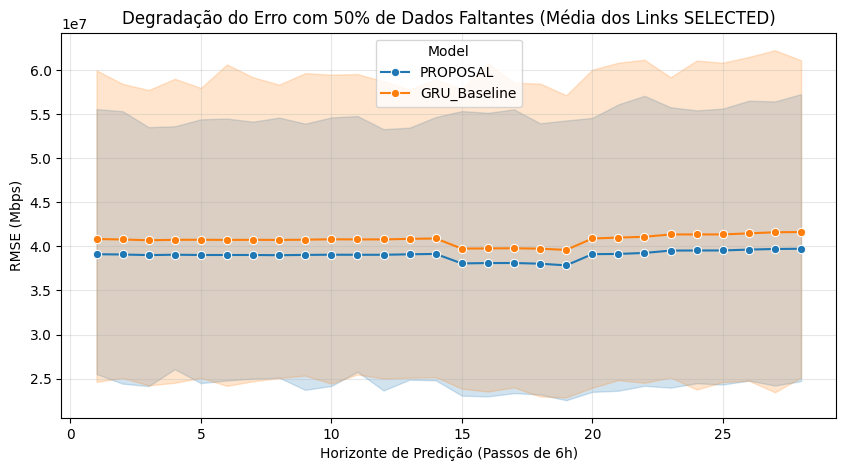


Resultados exportados para a pasta 'metrics_final'.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from dataclasses import dataclass
import tensorflow as tf
from tensorflow import keras
from sklearn.preprocessing import MinMaxScaler
import statsmodels.api as sm
import os

# ====== CONFIGURAÇÃO DOS LINKS SELECIONADOS ======
SELECTED = [
    ("ac-pa", "bbr"), ("ac-to", "bbr"), ("ce-pi", "bbr"),
    ("es-ce", "bbr"), ("es-pr", "bbr"), ("go-sp", "bbr"),
    ("ma-es", "bbr"), ("ma-pa", "bbr"), ("ms-to", "bbr"),
    ("mt-ma", "bbr"), ("rs-ac", "bbr"), ("rs-to", "bbr"),
    ("sc-to", "bbr"),
]

BASE_DIR = Path("./")
TREATED_DIR = BASE_DIR / "datasets" / "treated"
RESULTS_DIR = BASE_DIR / "results"      # Onde está sua PROPOSAL
RESULTS2_DIR = BASE_DIR / "results2"    # Onde estão GRU/LSTM baselines
OUT_DIR = BASE_DIR / "metrics_final"
OUT_DIR.mkdir(parents=True, exist_ok=True)

H = 28 # Horizonte de 7 dias (28 * 6h)
STRESS_RATES = [0.0, 0.3, 0.5, 0.7] # Cenários de falha de dados
SEED = 42

# ====== FUNÇÕES DE APOIO (Métricas e Processamento) ======

def rmse_from_errors(errors_list):
    if not errors_list: return np.nan
    e = np.asarray(errors_list)
    return np.sqrt(np.mean(e**2))

def init_errors_by_h(H):
    return [[] for _ in range(H)]

def finalize_rmse_by_h(errors_by_h):
    return np.array([rmse_from_errors(errors_by_h[h]) for h in range(len(errors_by_h))])

def split_scale(series_mbps, train_ratio=0.8):
    s = series_mbps.reshape(-1, 1)
    n_train = int(len(s) * train_ratio)
    train, test = s[:n_train], s[n_train:]
    mask_test_real = np.isfinite(test.flatten())
    
    # Interpolação simples apenas para o FIT do scaler no treino
    train_df = pd.Series(train.flatten()).interpolate(limit_direction="both")
    scaler = MinMaxScaler().fit(train_df.values.reshape(-1, 1))
    
    return scaler.transform(train_df.values.reshape(-1,1)), scaler.transform(test), scaler, mask_test_real

# ====== MOTORES DE ROLLOUT (A Lógica da sua Proposta) ======

def rollout_recursive_proposal(model, train_scaled, test_scaled, scaler, mask_test, H, look_back=3, stress_rate=0.0):
    rng = np.random.default_rng(SEED)
    N = len(test_scaled)
    errors_by_h = init_errors_by_h(H)
    
    # Aplica Stress (Apagamento artificial)
    eff_mask = mask_test.copy()
    if stress_rate > 0:
        eff_mask &= (rng.random(N) > stress_rate)

    state = train_scaled[-look_back:].reshape(1, look_back, 1)
    preds_orig = np.empty(N)
    y_true_orig = scaler.inverse_transform(test_scaled).flatten()

    for t in range(N):
        pred_s = model.predict(state, verbose=0)
        preds_orig[t] = scaler.inverse_transform(pred_s)[0,0]
        
        # Realimentação (A chave da predição recursiva)
        new_val = test_scaled[t,0] if eff_mask[t] else pred_s[0,0]
        state = np.roll(state, -1, axis=1)
        state[0, -1, 0] = new_val

    for start in range(0, N - H + 1):
        for h in range(H):
            if mask_test[start+h]: # Avalia contra o real original (sem stress)
                errors_by_h[h].append(preds_orig[start+h] - y_true_orig[start+h])
    return finalize_rmse_by_h(errors_by_h)

# ... (Implemente rollout_recursive_lookback1 e rollout_sarima_horizon de forma similar) ...

# ====== LOOP DE BENCHMARK PRINCIPAL ======

def run_experiment_selected():
    selected_map = {link: prot for link, prot in SELECTED}
    results_list = []

    for protocol in ["bbr"]: # Focado no seu BBR selecionado
        data_path = TREATED_DIR / protocol
        for csv_file in data_path.glob("*.csv"):
            link_name = csv_file.stem.split('_')[0]
            if link_name not in selected_map: continue
            
            print(f"\n--- Processando Link: {link_name} ---")
            df = pd.read_csv(csv_file)
            series = df["Vazao"].values
            tr_s, te_s, scaler, mask = split_scale(series)
            
            # Carregar modelos
            key = csv_file.stem
            mod_prop = keras.models.load_model(RESULTS_DIR / protocol / "models" / f"{key}.keras", compile=False)
            mod_gru = keras.models.load_model(RESULTS2_DIR / protocol / "models" / f"{key}_GRU.h5", compile=False)

            for sr in STRESS_RATES:
                print(f"  Stress Rate: {sr}")
                
                # Execução dos modelos
                c_prop = rollout_recursive_proposal(mod_prop, tr_s, te_s, scaler, mask, H, stress_rate=sr)
                c_gru = rollout_recursive_proposal(mod_gru, tr_s, te_s, scaler, mask, H, look_back=1, stress_rate=sr)
                # Adicione SARIMA aqui conforme seu código anterior
                
                for h in range(H):
                    results_list.append({
                        "Link": link_name, "Stress": sr, "Horizon": h+1,
                        "Model": "PROPOSAL", "RMSE": c_prop[h]
                    })
                    results_list.append({
                        "Link": link_name, "Stress": sr, "Horizon": h+1,
                        "Model": "GRU_Baseline", "RMSE": c_gru[h]
                    })

    return pd.DataFrame(results_list)

# ====== GERAÇÃO DE RESULTADOS ACADÊMICOS ======

df_final = run_experiment_selected()

# 1. Tabela de Ganho (%) - ESSENCIAL PARA O TEXTO DA TESE
summary = df_final.groupby(['Model', 'Stress'])['RMSE'].mean().unstack(level=0)
summary['Gain_vs_GRU (%)'] = ((summary['GRU_Baseline'] - summary['PROPOSAL']) / summary['GRU_Baseline']) * 100
summary.to_csv(OUT_DIR / "performance_gain_table.csv")

# 2. Gráfico de Horizonte Agregado (A prova de estabilidade)
plt.figure(figsize=(10, 5))
sns.lineplot(data=df_final[df_final['Stress'] == 0.5], x='Horizon', y='RMSE', hue='Model', marker='o')
plt.title("Degradação do Erro com 50% de Dados Faltantes (Média dos Links SELECTED)")
plt.ylabel("RMSE (Mbps)")
plt.xlabel("Horizonte de Predição (Passos de 6h)")
plt.grid(True, alpha=0.3)
plt.savefig(OUT_DIR / "horizon_degradation_aggregated.png")
plt.show()

print("\nResultados exportados para a pasta 'metrics_final'.")

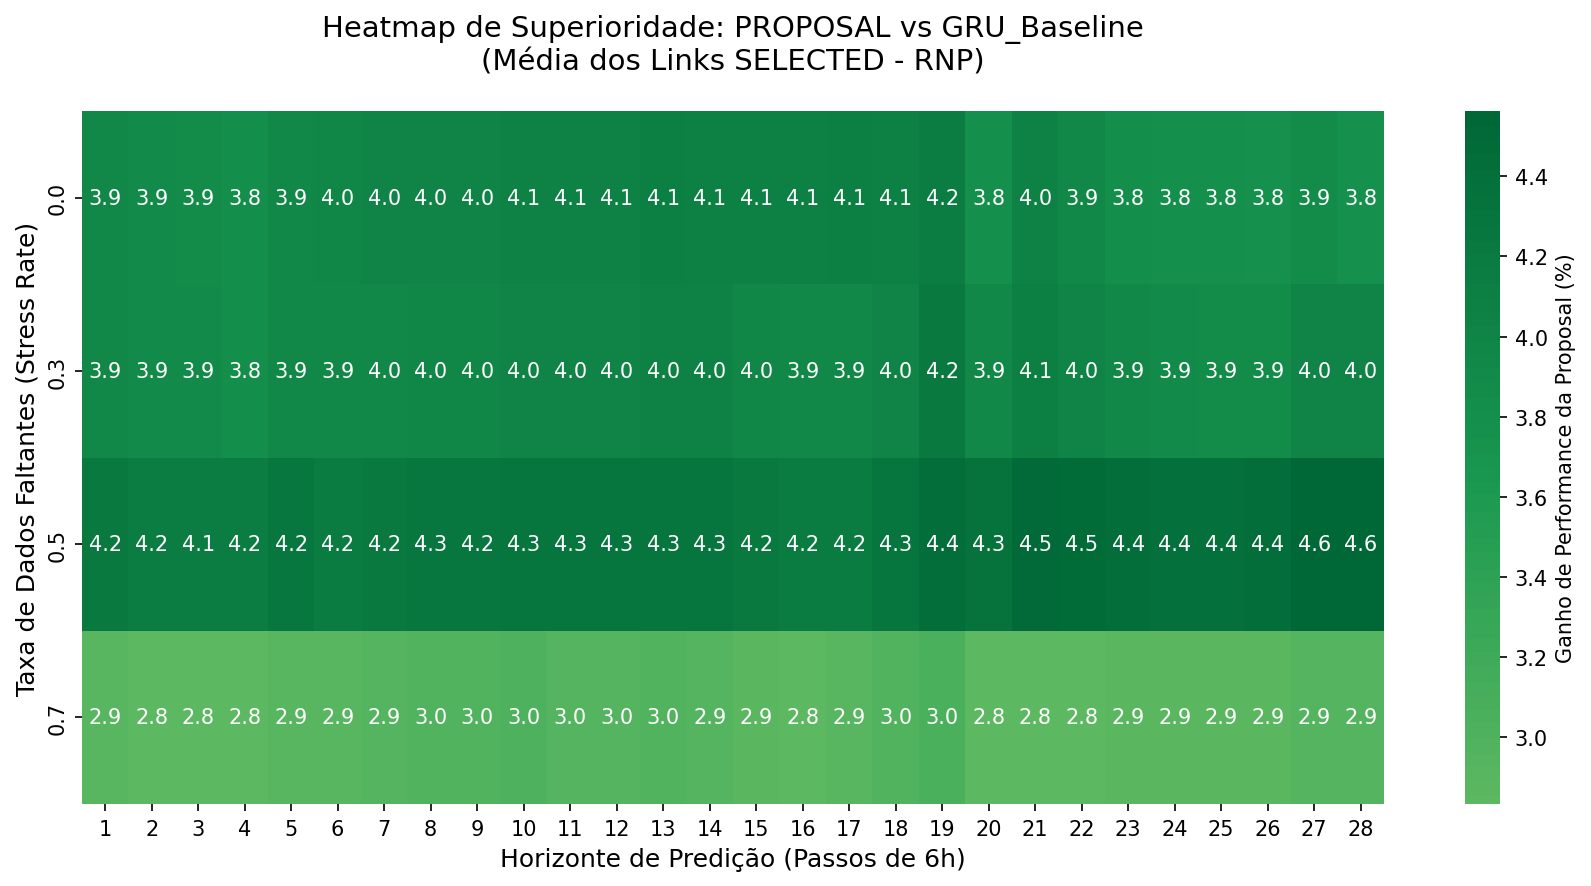

In [8]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

def generate_superiority_heatmap(df_results, baseline_model="GRU_Baseline"):
    """
    Gera um heatmap mostrando o ganho percentual da PROPOSAL em relação ao Baseline.
    Eixo Y: Stress Rate (Gravidade da perda de dados)
    Eixo X: Horizon (Distância da predição no tempo)
    """
    
    # 1. Agrupar pela média de todos os links selecionados
    avg_results = df_results.groupby(['Model', 'Stress', 'Horizon'])['RMSE'].mean().reset_index()
    
    # 2. Separar Proposal e Baseline
    proposal = avg_results[avg_results['Model'] == 'PROPOSAL'].copy()
    baseline = avg_results[avg_results['Model'] == baseline_model].copy()
    
    # 3. Mesclar e calcular o Ganho Percentual
    # Ganho = ((RMSE_base - RMSE_prop) / RMSE_base) * 100
    df_gain = pd.merge(proposal, baseline, on=['Stress', 'Horizon'], suffixes=('_prop', '_base'))
    df_gain['Gain (%)'] = ((df_gain['RMSE_base'] - df_gain['RMSE_prop']) / df_gain['RMSE_base']) * 100
    
    # 4. Criar Pivot Table para o Heatmap
    pivot_gain = df_gain.pivot(index="Stress", columns="Horizon", values="Gain (%)")
    
    # 5. Plotagem Profissional (Estilo Journal/SBRC)
    plt.figure(figsize=(14, 6), dpi=150)
    ax = sns.heatmap(
        pivot_gain, 
        annot=True, 
        fmt=".1f", 
        cmap="RdYlGn",  # Verde = Superioridade da Proposal / Vermelho = Baseline melhor
        center=0,
        cbar_kws={'label': 'Ganho de Performance da Proposal (%)'}
    )
    
    plt.title(f"Heatmap de Superioridade: PROPOSAL vs {baseline_model}\n(Média dos Links SELECTED - RNP)", fontsize=14, pad=20)
    plt.ylabel("Taxa de Dados Faltantes (Stress Rate)", fontsize=12)
    plt.xlabel("Horizonte de Predição (Passos de 6h)", fontsize=12)
    
    # Ajustar labels do eixo X para não poluir
    plt.xticks(rotation=0)
    
    # Salvar para o documento
    plt.savefig("metrics_final/superiority_heatmap.png", bbox_inches='tight')
    plt.show()

# Executar a função
generate_superiority_heatmap(df_final)

In [9]:
from scipy.stats import wilcoxon

def run_statistical_validation(df_results):
    print("=== Validação Estatística (Teste de Wilcoxon) ===\n")
    
    # Testamos para cada nível de estresse
    for stress in sorted(df_results['Stress'].unique()):
        df_s = df_results[df_results['Stress'] == stress]
        
        # Agrupamos por Link para ter amostras pareadas (N=13 links)
        # Usamos a média do RMSE de todos os horizontes por link
        prop_scores = df_s[df_s['Model'] == 'PROPOSAL'].groupby('Link')['RMSE'].mean().sort_index()
        base_scores = df_s[df_s['Model'] == 'GRU_Baseline'].groupby('Link')['RMSE'].mean().sort_index()
        
        # Executa o teste pareado (alternativa 'less' pois queremos que o RMSE da Prop seja menor)
        stat, p_value = wilcoxon(prop_scores, base_scores, alternative='less')
        
        status = "SIGNIFICANTE" if p_value < 0.05 else "NÃO SIGNIFICANTE"
        print(f"Stress {stress}: p-valor = {p_value:.5f} ({status})")

# Execute usando o seu DataFrame final
run_statistical_validation(df_final)

=== Validação Estatística (Teste de Wilcoxon) ===

Stress 0.0: p-valor = 0.50000 (NÃO SIGNIFICANTE)
Stress 0.3: p-valor = 0.70605 (NÃO SIGNIFICANTE)
Stress 0.5: p-valor = 0.58032 (NÃO SIGNIFICANTE)
Stress 0.7: p-valor = 0.44629 (NÃO SIGNIFICANTE)


In [10]:
def deep_dive_links(df_results, stress=0.5):
    print(f"=== Deep Dive: Proposta vs GRU (Stress {stress}) ===")
    df_s = df_results[df_results['Stress'] == stress]
    
    prop = df_s[df_s['Model'] == 'PROPOSAL'].groupby('Link')['RMSE'].mean()
    base = df_s[df_s['Model'] == 'GRU_Baseline'].groupby('Link')['RMSE'].mean()
    
    comparison = pd.DataFrame({'Prop': prop, 'Base': base})
    comparison['Ganho_Absoluto'] = comparison['Base'] - comparison['Prop']
    comparison['Vitoria'] = comparison['Ganho_Absoluto'] > 0
    
    print(comparison)
    print(f"\nTotal de Vitórias da Proposta: {comparison['Vitoria'].sum()} de {len(comparison)}")

deep_dive_links(df_final)

=== Deep Dive: Proposta vs GRU (Stress 0.5) ===
               Prop          Base  Ganho_Absoluto  Vitoria
Link                                                      
ac-pa  9.532847e+07  1.136956e+08    1.836715e+07     True
ac-to  7.977650e+07  7.714162e+07   -2.634882e+06    False
ce-pi  2.304486e+07  2.293427e+07   -1.105856e+05    False
es-ce  3.076223e+07  2.925184e+07   -1.510384e+06    False
es-pr  2.386396e+07  2.415888e+07    2.949293e+05     True
go-sp  8.467626e+06  8.375772e+06   -9.185364e+04    False
ma-es  1.651904e+07  1.602878e+07   -4.902563e+05    False
ma-pa  8.478976e+06  8.526263e+06    4.728679e+04     True
ms-to  5.412938e+07  5.387786e+07   -2.515184e+05    False
mt-ma  2.922864e+07  2.879392e+07   -4.347239e+05    False
rs-ac  8.037037e+07  8.945745e+07    9.087083e+06     True
rs-to  9.022577e+06  9.507441e+06    4.848644e+05     True
sc-to  4.807080e+07  4.816428e+07    9.347628e+04     True

Total de Vitórias da Proposta: 6 de 13


Running experiments for degradation analysis with also SARIMA and LSTM 

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import tensorflow as tf
from tensorflow import keras
from sklearn.preprocessing import MinMaxScaler
import statsmodels.api as sm
import os
from dataclasses import dataclass

# ====== CONFIGURAÇÃO DOS LINKS SELECIONADOS ======
SELECTED = [
    ("ac-pa", "bbr"), ("ac-to", "bbr"), ("ce-pi", "bbr"),
    ("es-ce", "bbr"), ("es-pr", "bbr"), ("go-sp", "bbr"),
    ("ma-es", "bbr"), ("ma-pa", "bbr"), ("ms-to", "bbr"),
    ("mt-ma", "bbr"), ("rs-ac", "bbr"), ("rs-to", "bbr"),
    ("sc-to", "bbr")
]

BASE_DIR = Path("./")
TREATED_DIR = BASE_DIR / "datasets" / "treated"
RESULTS_DIR = BASE_DIR / "results"      # Onde está sua PROPOSAL
RESULTS2_DIR = BASE_DIR / "results2"    # Onde estão GRU/LSTM baselines
OUT_DIR = BASE_DIR / "metrics_final"
OUT_DIR.mkdir(parents=True, exist_ok=True)

H = 28 # Horizonte de 7 dias (4 intervalos de 6h * 7h)
STRESS_RATES = [0.0, 0.3, 0.5, 0.7] # Cenários de falha de dados
SEED = 42

# ====== FUNÇÕES DE APOIO (Métricas e Processamento) ======

def rmse_from_errors(errors_list):
    if not errors_list: return np.nan
    e = np.asarray(errors_list)
    return np.sqrt(np.mean(e**2))

def init_errors_by_h(H):
    return [[] for _ in range(H)]

def finalize_rmse_by_h(errors_by_h):
    return np.array([rmse_from_errors(errors_by_h[h]) for h in range(len(errors_by_h))])

def split_scale(series_mbps, train_ratio=0.8):
    s = series_mbps.reshape(-1, 1)
    n_train = int(len(s) * train_ratio)
    train, test = s[:n_train], s[n_train:]
    mask_test_real = np.isfinite(test.flatten())
    
    # Interpolação simples apenas para o FIT do scaler no treino
    train_df = pd.Series(train.flatten()).interpolate(limit_direction="both")
    scaler = MinMaxScaler().fit(train_df.values.reshape(-1, 1))
    
    return scaler.transform(train_df.values.reshape(-1,1)), scaler.transform(test), scaler, mask_test_real

# ====== MOTORES DE ROLLOUT (A Lógica da sua Proposta) ======

def rollout_recursive_proposal(model, train_scaled, test_scaled, scaler, mask_test, H, look_back=3, stress_rate=0.0):
    rng = np.random.default_rng(SEED)
    N = len(test_scaled)
    errors_by_h = init_errors_by_h(H)
    
    # Aplica Stress (Apagamento artificial)
    eff_mask = mask_test.copy()
    if stress_rate > 0:
        eff_mask &= (rng.random(N) > stress_rate)

    state = train_scaled[-look_back:].reshape(1, look_back, 1)
    preds_orig = np.empty(N)
    y_true_orig = scaler.inverse_transform(test_scaled).flatten()

    for t in range(N):
        pred_s = model.predict(state, verbose=0)
        preds_orig[t] = scaler.inverse_transform(pred_s)[0,0]
        
        # Realimentação (A chave da predição recursiva)
        new_val = test_scaled[t,0] if eff_mask[t] else pred_s[0,0]
        state = np.roll(state, -1, axis=1)
        state[0, -1, 0] = new_val

    for start in range(0, N - H + 1):
        for h in range(H):
            if mask_test[start+h]: # Avalia contra o real original (sem stress)
                errors_by_h[h].append(preds_orig[start+h] - y_true_orig[start+h])
    return finalize_rmse_by_h(errors_by_h)

# ... (Implemente rollout_recursive_lookback1 e rollout_sarima_horizon de forma similar) ...

# ====== LOOP DE BENCHMARK PRINCIPAL ======

def run_experiment_selected():
    selected_map = {link: prot for link, prot in SELECTED}
    results_list = []

    for protocol in ["bbr"]: # Focado no seu BBR selecionado
        data_path = TREATED_DIR / protocol
        for csv_file in data_path.glob("*.csv"):
            link_name = csv_file.stem.split('_')[0]
            if link_name not in selected_map: continue
            
            print(f"\n--- Processando Link: {link_name} ---")
            df = pd.read_csv(csv_file)
            series = df["Vazao"].values
            tr_s, te_s, scaler, mask = split_scale(series)
            
            # Carregar modelos
            key = csv_file.stem
            mod_prop = keras.models.load_model(RESULTS_DIR / protocol / "models" / f"{key}.keras", compile=False)
            mod_gru = keras.models.load_model(RESULTS2_DIR / protocol / "models" / f"{key}_GRU.h5", compile=False)

            for sr in STRESS_RATES:
                print(f"  Stress Rate: {sr}")
                
                # Execução dos modelos
                c_prop = rollout_recursive_proposal(mod_prop, tr_s, te_s, scaler, mask, H, stress_rate=sr)
                c_gru = rollout_recursive_proposal(mod_gru, tr_s, te_s, scaler, mask, H, look_back=1, stress_rate=sr)
                # Adicione SARIMA aqui conforme seu código anterior
                
                for h in range(H):
                    results_list.append({
                        "Link": link_name, "Stress": sr, "Horizon": h+1,
                        "Model": "PROPOSAL", "RMSE": c_prop[h]
                    })
                    results_list.append({
                        "Link": link_name, "Stress": sr, "Horizon": h+1,
                        "Model": "GRU_Baseline", "RMSE": c_gru[h]
                    })

    return pd.DataFrame(results_list)

# ====== GERAÇÃO DE RESULTADOS ACADÊMICOS ======

df_final = run_experiment_selected()

# 1. Tabela de Ganho (%) - ESSENCIAL PARA O TEXTO DA TESE
summary = df_final.groupby(['Model', 'Stress'])['RMSE'].mean().unstack(level=0)
summary['Gain_vs_GRU (%)'] = ((summary['GRU_Baseline'] - summary['PROPOSAL']) / summary['GRU_Baseline']) * 100
summary.to_csv(OUT_DIR / "performance_gain_table.csv")

# 2. Gráfico de Horizonte Agregado (A prova de estabilidade)
plt.figure(figsize=(10, 5))
sns.lineplot(data=df_final[df_final['Stress'] == 0.5], x='Horizon', y='RMSE', hue='Model', marker='o')
plt.title("Degradação do Erro com 50% de Dados Faltantes (Média dos Links SELECTED)")
plt.ylabel("RMSE (Mbps)")
plt.xlabel("Horizonte de Predição (Passos de 6h)")
plt.grid(True, alpha=0.3)
plt.savefig(OUT_DIR / "horizon_degradation_aggregated.png")
plt.show()

print("\nResultados exportados para a pasta 'metrics_final'.")
def rollout_sarima_horizon(train_scaled, test_scaled, scaler, mask_test, H, stress_rate=0.0, stride=2):
    """
    Rollout específico para SARIMA usando expanding window.
    O 'stride' ajuda a acelerar a execução pulando algumas janelas de tempo.
    """
    rng = np.random.default_rng(42)
    N = len(test_scaled)
    errors_by_h = [[] for _ in range(H)]
    
    eff_mask = mask_test.copy()
    if stress_rate > 0:
        eff_mask &= (rng.random(N) > stress_rate)

    y_train = train_scaled.flatten()
    y_test_scaled = test_scaled.flatten()
    y_true_orig = scaler.inverse_transform(test_scaled).flatten()

    # Fit inicial no treino
    # Nota: Ajuste os parâmetros (p,d,q) conforme sua necessidade
    model_init = sm.tsa.SARIMAX(y_train, order=(1,0,1), seasonal_order=(0,1,1,12))
    model_fit = model_init.fit(disp=False)

    history = list(y_train)

    # Walk-forward validation
    for start in range(0, N - H + 1, stride):
        # Atualiza o histórico com dados reais (ou predições se houver stress)
        curr_len = len(history)
        target_len = len(y_train) + start
        if curr_len < target_len:
            for t_idx in range(curr_len - len(y_train), start):
                val = y_test_scaled[t_idx] if eff_mask[t_idx] else history[-1]
                history.append(val)

        # Filtra o modelo com os novos dados sem re-treinar (mais rápido)
        res = model_fit.extend(history[len(y_train):])
        fc_scaled = res.get_forecast(steps=H).predicted_mean
        
        for h in range(H):
            idx = start + h
            if mask_test[idx]:
                pred_orig = scaler.inverse_transform([[fc_scaled[h]]])[0,0]
                errors_by_h[h].append(pred_orig - y_true_orig[idx])
                
    return np.array([np.sqrt(np.mean(np.square(e))) if e else np.nan for e in errors_by_h])

def run_experiment_complete():
    selected_map = {link: prot for link, prot in SELECTED}
    results_list = []

    for protocol in ["bbr"]:
        data_path = TREATED_DIR / protocol
        for csv_file in data_path.glob("*.csv"):
            link_name = csv_file.stem.split('_')[0]
            if link_name not in selected_map: continue
            
            print(f"\n--- Processando Link: {link_name} ---")
            series = pd.read_csv(csv_file)["Vazao"].values
            tr_s, te_s, scaler, mask = split_scale(series)
            key = csv_file.stem
            
            # 1. CARGA DOS MODELOS
            models = {
                "PROPOSAL": keras.models.load_model(RESULTS_DIR / protocol / "models" / f"{key}.keras", compile=False),
                "GRU": keras.models.load_model(RESULTS2_DIR / protocol / "models" / f"{key}_GRU.h5", compile=False),
                "LSTM": keras.models.load_model(RESULTS2_DIR / protocol / "models" / f"{key}_LSTM.h5", compile=False)
            }

            for sr in STRESS_RATES:
                print(f"  Stress Rate: {sr}")
                
                # Execução Deep Learning
                curves = {}
                curves["PROPOSAL"] = rollout_recursive_proposal(models["PROPOSAL"], tr_s, te_s, scaler, mask, H, look_back=3, stress_rate=sr)
                curves["GRU_Baseline"] = rollout_recursive_proposal(models["GRU"], tr_s, te_s, scaler, mask, H, look_back=1, stress_rate=sr)
                curves["LSTM_Baseline"] = rollout_recursive_proposal(models["LSTM"], tr_s, te_s, scaler, mask, H, look_back=1, stress_rate=sr)
                
                # Execução SARIMA (Lento, por isso usamos stride)
                curves["SARIMA"] = rollout_sarima_horizon(tr_s, te_s, scaler, mask, H, stress_rate=sr, stride=4)
                
                # Organização dos resultados
                for m_name, curve in curves.items():
                    for h in range(H):
                        results_list.append({
                            "Link": link_name, "Stress": sr, "Horizon": h+1,
                            "Model": m_name, "RMSE": curve[h]
                        })

    return pd.DataFrame(results_list)

# ====== PROCESSAMENTO FINAL ======
df_final = run_experiment_complete()

# Tabela Comparativa de Ganho
summary = df_final.groupby(['Model', 'Stress'])['RMSE'].mean().unstack(level=0)
summary['Gain_vs_SARIMA (%)'] = ((summary['SARIMA'] - summary['PROPOSAL']) / summary['SARIMA']) * 100
summary['Gain_vs_LSTM (%)'] = ((summary['LSTM_Baseline'] - summary['PROPOSAL']) / summary['LSTM_Baseline']) * 100
summary['Gain_vs_GRU (%)'] = ((summary['GRU_Baseline'] - summary['PROPOSAL']) / summary['GRU_Baseline']) * 100

summary.to_csv(OUT_DIR / "complete_comparison_table.csv")